# Do sinal ao espectro: um analisador e filtro de sinais
**Sistematização · Métodos Matemáticos — CEUB**

| | |
|---|---|
| **Integrante(s)** | Julio Cesar Sousa Oliveira — RA 22308014 |
| **Sinal escolhido** | **Sinal biomédico (ECG)** — registro 208 do *MIT-BIH Arrhythmia Database* (PhysioNet), 360 Hz |
| **Problema** | Remover deriva de linha de base, interferência da rede elétrica (60 Hz) e ruído de alta frequência sem deformar o complexo QRS |
| **Ferramentas** | Python · `numpy` · `matplotlib` · `scipy.fft` · `scipy.signal` · `sympy` |

**Roteiro do notebook**

1. **Etapa 1 — Série de Fourier (Un. 1 e 2):** onda quadrada, coeficientes, forma complexa, convergência e fenômeno de Gibbs, ortogonalidade.
2. **Etapa 2 — Do tempo para a frequência (Un. 3):** FFT do ECG, leitura do espectro, taxa de amostragem, Nyquist e *aliasing*.
3. **Etapa 3 — Filtrar e reconstruir (Un. 3):** filtro no domínio da frequência + **FFT inversa**, comparação antes/depois.
4. **Etapa 4 — O filtro como sistema linear (Un. 4):** função de transferência $H(s)$ via Laplace, mapa de polos e zeros, estabilidade e ligação com a Etapa 2.

> Para rodar no Google Colab: *Ambiente de execução → Executar tudo*. O notebook baixa o sinal sozinho caso a pasta `dados/` não esteja presente.

In [1]:
import os, sys, subprocess
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.fft import rfft, irfft, rfftfreq
import sympy as sp

plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
os.makedirs("figuras", exist_ok=True)
os.makedirs("dados", exist_ok=True)

def salvar(fig, nome):
    # Guarda cada gráfico em figuras/ (útil para o relatório e o vídeo).
    fig.savefig(f"figuras/{nome}.png", dpi=120, bbox_inches="tight")

np.random.seed(42)  # reprodutibilidade do ruído sintético
if not hasattr(np, "trapezoid"):   # numpy < 2.0 (versões antigas do Colab)
    np.trapezoid = np.trapz

---
# Etapa 1 · Aproximando funções com ondas (Unidades 1 e 2)

Vamos aproximar a **onda quadrada** de período $T = 2\pi$:

$$
f(t) = \begin{cases} -1, & -\pi < t < 0 \\ \phantom{-}1, & \phantom{-}0 < t < \pi \end{cases}, \qquad f(t + 2\pi) = f(t)
$$

A Série de Fourier trigonométrica é

$$
f(t) \sim \frac{a_0}{2} + \sum_{n=1}^{\infty} \big[a_n \cos(nt) + b_n \sin(nt)\big],
\quad a_n = \frac{1}{\pi}\int_{-\pi}^{\pi} f(t)\cos(nt)\,dt,
\quad b_n = \frac{1}{\pi}\int_{-\pi}^{\pi} f(t)\sin(nt)\,dt.
$$

Como $f$ é **ímpar**, $f(t)\cos(nt)$ é ímpar e integra a zero: $a_0 = a_n = 0$. Sobram só os senos.

## 1.1 Coeficientes — cálculo simbólico (sympy)

In [2]:
t, n = sp.symbols("t n", real=True)
n_int = sp.symbols("n", integer=True, positive=True)

a0 = (1/sp.pi) * (sp.integrate(-1, (t, -sp.pi, 0)) + sp.integrate(1, (t, 0, sp.pi)))
an = (1/sp.pi) * (sp.integrate(-sp.cos(n_int*t), (t, -sp.pi, 0)) + sp.integrate(sp.cos(n_int*t), (t, 0, sp.pi)))
bn = (1/sp.pi) * (sp.integrate(-sp.sin(n_int*t), (t, -sp.pi, 0)) + sp.integrate(sp.sin(n_int*t), (t, 0, sp.pi)))

print("a0 =", sp.simplify(a0))
print("an =", sp.simplify(an))
print("bn =", sp.simplify(bn))
print("bn para n = 1..7:", [sp.simplify(bn.subs(n_int, k)) for k in range(1, 8)])

a0 = 0
an = 0
bn = 2*(1 - (-1)**n)/(pi*n)
bn para n = 1..7: [4/pi, 0, 4/(3*pi), 0, 4/(5*pi), 0, 4/(7*pi)]


O resultado é $b_n = \dfrac{2\,(1-(-1)^n)}{n\pi}$, ou seja:

$$
b_n = \begin{cases} \dfrac{4}{n\pi}, & n \text{ ímpar} \\[4pt] 0, & n \text{ par} \end{cases}
\qquad\Longrightarrow\qquad
f(t) = \frac{4}{\pi}\left[\sin t + \frac{\sin 3t}{3} + \frac{\sin 5t}{5} + \cdots\right]
$$

## 1.2 Conferindo numericamente
Calculamos as mesmas integrais por soma numérica (regra do trapézio) e comparamos com a fórmula.

In [3]:
def onda_quadrada(t):
    # Onda quadrada de período 2π, amplitude 1 (vale 0 exatamente nas descontinuidades).
    # (arredondar evita que sin(π) ≈ 1e-16 vire ±1 por erro de ponto flutuante)
    return np.sign(np.round(np.sin(t), 12))

tt = np.linspace(-np.pi, np.pi, 200_001)
ft = onda_quadrada(tt)

print(" n |  a_n (num.) |  b_n (num.) |  b_n (fórmula)")
for k in range(1, 10):
    a_num = np.trapezoid(ft * np.cos(k*tt), tt) / np.pi
    b_num = np.trapezoid(ft * np.sin(k*tt), tt) / np.pi
    b_teo = 4/(k*np.pi) if k % 2 else 0.0
    print(f"{k:2d} | {a_num:+.6f}   | {b_num:+.6f}   | {b_teo:+.6f}")

 n |  a_n (num.) |  b_n (num.) |  b_n (fórmula)
 1 | +0.000000   | +1.273240   | +1.273240
 2 | +0.000000   | -0.000000   | +0.000000
 3 | +0.000000   | +0.424413   | +0.424413
 4 | +0.000000   | -0.000000   | +0.000000
 5 | +0.000000   | +0.254648   | +0.254648
 6 | +0.000000   | -0.000000   | +0.000000
 7 | +0.000000   | +0.181891   | +0.181891
 8 | +0.000000   | -0.000000   | +0.000000
 9 | +0.000000   | +0.141471   | +0.141471


## 1.3 Somas parciais: somando cada vez mais harmônicos
$S_K(t)$ = soma dos $K$ primeiros termos não nulos (harmônicos $1, 3, 5, \dots, 2K-1$).

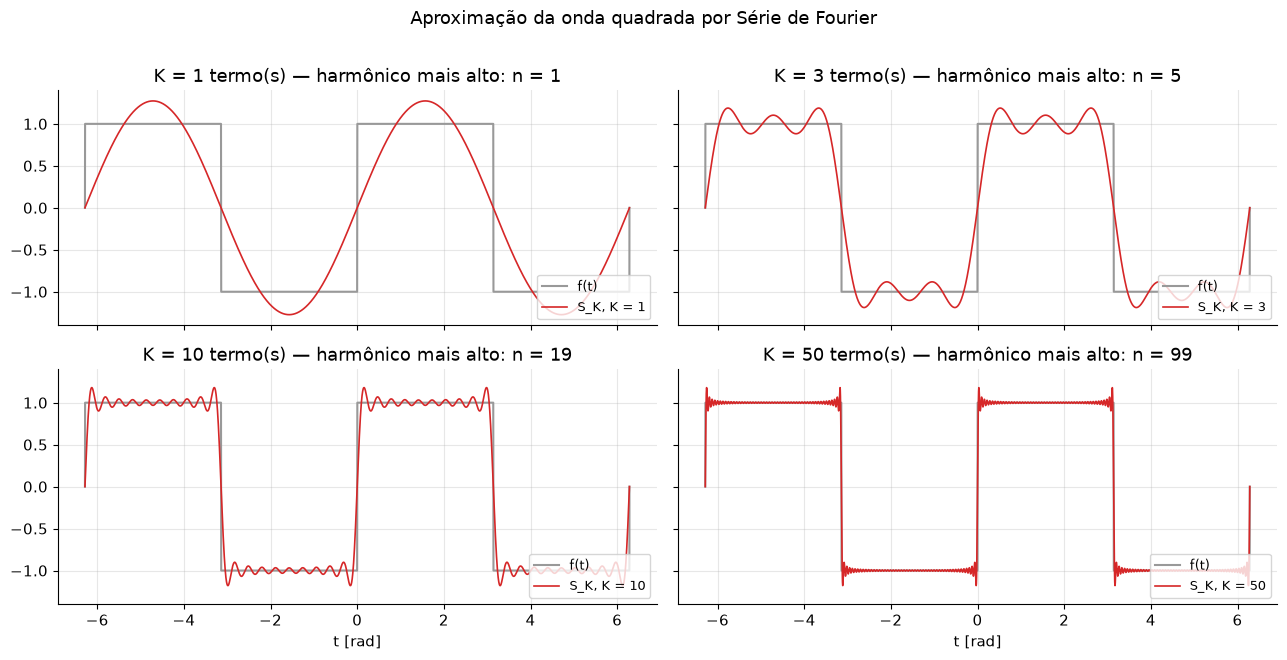

In [4]:
def soma_parcial(t, K):
    # S_K(t) = (4/π) Σ_{k=1..K} sin((2k-1)t)/(2k-1)
    s = np.zeros_like(t)
    for k in range(1, K + 1):
        m = 2*k - 1
        s += (4/(np.pi*m)) * np.sin(m*t)
    return s

tp = np.linspace(-2*np.pi, 2*np.pi, 8001)
fig, axs = plt.subplots(2, 2, figsize=(13, 6.5), sharex=True, sharey=True)
for ax, K in zip(axs.flat, [1, 3, 10, 50]):
    ax.plot(tp, onda_quadrada(tp), color="0.6", lw=1.5, label="f(t)")
    ax.plot(tp, soma_parcial(tp, K), color="C3", lw=1.2, label=f"S_K, K = {K}")
    ax.set_title(f"K = {K} termo(s) — harmônico mais alto: n = {2*K-1}")
    ax.legend(loc="lower right", fontsize=9)
for ax in axs[1]: ax.set_xlabel("t [rad]")
fig.suptitle("Aproximação da onda quadrada por Série de Fourier", y=1.01)
fig.tight_layout(); salvar(fig, "e1_somas_parciais"); plt.show()

**Leitura.** Com $K = 1$ temos só uma senoide com a mesma frequência e "o mesmo jeito" da quadrada. Cada harmônico ímpar adicionado deixa os patamares mais planos e as transições mais íngremes: os harmônicos altos são responsáveis pelas **bordas rápidas**, os baixos pela **forma geral**. Essa é a mesma ideia que usaremos no ECG: o QRS (pico estreito) vive em frequências mais altas que a onda T (larga e suave).

## 1.4 Fenômeno de Gibbs e convergência
Perto de cada salto aparece um "chifre" que **não diminui de altura** quando aumentamos $K$ — ele só fica mais estreito.

Limite teórico do pico: (2/π)·Si(π) = 1.17898  →  overshoot de 8.95% do salto
K =   1: pico = 1.27324  (overshoot 13.66% do salto)   erro RMS = 0.4352
K =   2: pico = 1.20042  (overshoot 10.02% do salto)   erro RMS = 0.3152
K =   5: pico = 1.18233  (overshoot  9.12% do salto)   erro RMS = 0.2010
K =  10: pico = 1.17981  (overshoot  8.99% do salto)   erro RMS = 0.1423
K =  20: pico = 1.17919  (overshoot  8.96% do salto)   erro RMS = 0.1007
K =  50: pico = 1.17901  (overshoot  8.95% do salto)   erro RMS = 0.0637
K = 100: pico = 1.17899  (overshoot  8.95% do salto)   erro RMS = 0.0450
K = 200: pico = 1.17898  (overshoot  8.95% do salto)   erro RMS = 0.0319
K = 500: pico = 1.17898  (overshoot  8.95% do salto)   erro RMS = 0.0202


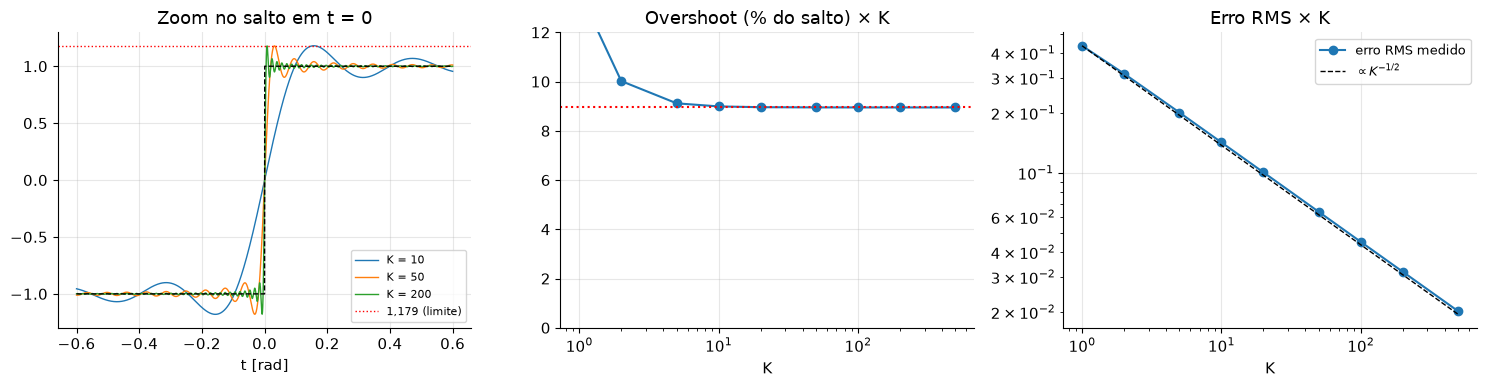

In [5]:
Ks = np.array([1, 2, 5, 10, 20, 50, 100, 200, 500])
t_fino = np.linspace(1e-6, np.pi - 1e-6, 400_001)   # meio período, sem os pontos de salto
picos, erros_rms = [], []
for K in Ks:
    s = soma_parcial(t_fino, K)
    picos.append(s.max())
    erros_rms.append(np.sqrt(np.mean((s - 1.0)**2)))
picos, erros_rms = np.array(picos), np.array(erros_rms)

from scipy.special import sici
gibbs_teo = (2/np.pi) * sici(np.pi)[0]                # valor-limite: (2/π)·Si(π)
print(f"Limite teórico do pico: (2/π)·Si(π) = {gibbs_teo:.5f}  →  overshoot de {(gibbs_teo-1)/2*100:.2f}% do salto")
for K, p, e in zip(Ks, picos, erros_rms):
    print(f"K = {K:3d}: pico = {p:.5f}  (overshoot {(p-1)/2*100:5.2f}% do salto)   erro RMS = {e:.4f}")

fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(15, 4))
tz = np.linspace(-0.6, 0.6, 6001)
for K in [10, 50, 200]:
    a1.plot(tz, soma_parcial(tz, K), lw=1, label=f"K = {K}")
a1.plot(tz, onda_quadrada(tz), "k--", lw=1)
a1.axhline(gibbs_teo, color="r", ls=":", lw=1, label="1,179 (limite)")
a1.set_title("Zoom no salto em t = 0"); a1.set_xlabel("t [rad]"); a1.legend(fontsize=8)
a2.semilogx(Ks, (picos - 1)/2*100, "o-"); a2.axhline((gibbs_teo-1)/2*100, color="r", ls=":")
a2.set_title("Overshoot (% do salto) × K"); a2.set_xlabel("K"); a2.set_ylim(0, 12)
a3.loglog(Ks, erros_rms, "o-", label="erro RMS medido")
a3.loglog(Ks, erros_rms[0]*Ks**-0.5, "k--", lw=1, label=r"$\propto K^{-1/2}$")
a3.set_title("Erro RMS × K"); a3.set_xlabel("K"); a3.legend(fontsize=9)
fig.tight_layout(); salvar(fig, "e1_gibbs"); plt.show()

**Leitura (Gibbs).** O pico da soma parcial tende a $\frac{2}{\pi}\mathrm{Si}(\pi) \approx 1{,}179$, isto é, um *overshoot* de ≈ **9 % do salto** (o salto vai de −1 a +1), e esse valor **não cai** com $K$. Ao mesmo tempo, o **erro RMS cai** (≈ $K^{-1/2}$): a série converge **em média quadrática** (a energia do erro vai a zero), mas **não converge uniformemente** perto das descontinuidades. Em cada ponto de salto a série converge para a **média** dos limites laterais, $\frac{-1+1}{2} = 0$.

**Consequência prática:** quando um filtro corta frequências de forma muito abrupta ("filtro ideal"), ele está truncando a série — e aparecem oscilações (*ringing*) junto às bordas rápidas do sinal. Por isso, na Etapa 3, usaremos um filtro de transição suave (Butterworth) em vez de um "corte reto" no espectro.

## 1.5 Forma complexa da série
$$
f(t) = \sum_{n=-\infty}^{\infty} c_n\, e^{jnt}, \qquad c_n = \frac{1}{2\pi}\int_{-\pi}^{\pi} f(t)\,e^{-jnt}\,dt = \frac{a_n - j\,b_n}{2}
$$
Para a onda quadrada: $c_n = -\dfrac{2j}{n\pi}$ para $n$ ímpar, $c_n = 0$ para $n$ par, e $c_{-n} = \overline{c_n}$ (sinal real ⇒ simetria conjugada).

n  |  c_n numérico          |  c_n teórico
-3 | +0.0000 +0.2122j     | -0.0000 +0.2122j
-1 | +0.0000 +0.6366j     | -0.0000 +0.6366j
+0 | +0.0000 +0.0000j     | +0.0000 +0.0000j
+1 | +0.0000 -0.6366j     | -0.0000 -0.6366j
+2 | +0.0000 +0.0000j     | +0.0000 +0.0000j
+3 | +0.0000 -0.2122j     | -0.0000 -0.2122j
+5 | +0.0000 -0.1273j     | -0.0000 -0.1273j

máx |S_complexa − S_trig| = 1.11e-15   (mesma série, outra notação)
Parte imaginária da soma complexa (deve ser ~0): 2.81e-16


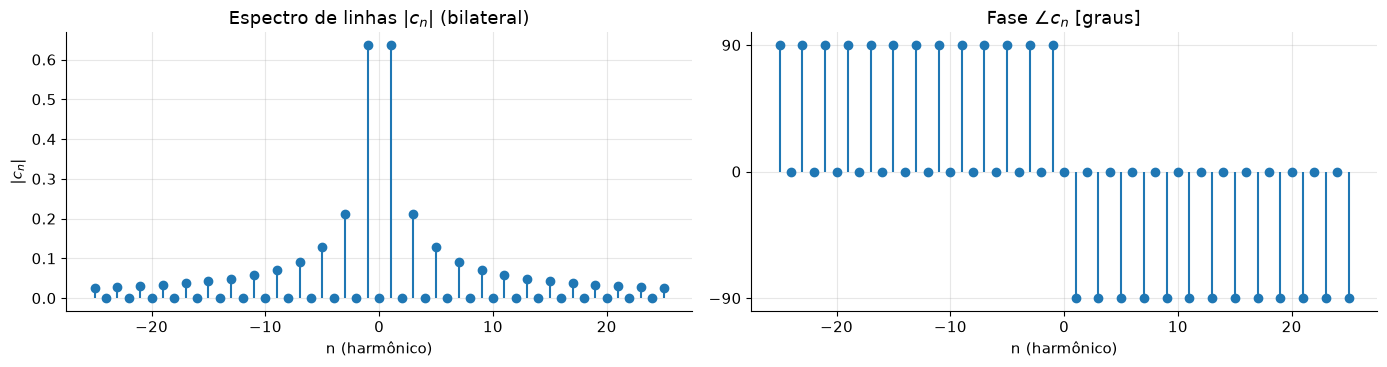

In [6]:
M = 25                                   # usa n = -M..M
ns = np.arange(-M, M + 1)
cn_num = np.array([np.trapezoid(ft * np.exp(-1j*k*tt), tt) / (2*np.pi) for k in ns])
cn_teo = np.where(ns % 2 != 0, -2j/(np.pi*np.where(ns == 0, 1, ns)), 0)

print("n  |  c_n numérico          |  c_n teórico")
for k in [-3, -1, 0, 1, 2, 3, 5]:
    i = k + M
    print(f"{k:+d} | {cn_num[i].real:+.4f} {cn_num[i].imag:+.4f}j     | {cn_teo[i].real:+.4f} {cn_teo[i].imag:+.4f}j")

# Reconstrução pela forma complexa = reconstrução pela forma trigonométrica?
S_complexa = np.real(sum(c * np.exp(1j*k*tp) for k, c in zip(ns, cn_teo)))
S_trig = soma_parcial(tp, (M + 1)//2)
print(f"\nmáx |S_complexa − S_trig| = {np.max(np.abs(S_complexa - S_trig)):.2e}   (mesma série, outra notação)")
print(f"Parte imaginária da soma complexa (deve ser ~0): {np.max(np.abs(np.imag(sum(c*np.exp(1j*k*tp) for k, c in zip(ns, cn_teo))))):.2e}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 3.8))
a1.stem(ns, np.abs(cn_num), basefmt=" ")
a1.set_title(r"Espectro de linhas $|c_n|$ (bilateral)"); a1.set_xlabel("n (harmônico)"); a1.set_ylabel(r"$|c_n|$")
a2.stem(ns, np.angle(cn_num)*180/np.pi*(np.abs(cn_num) > 1e-6), basefmt=" ")
a2.set_title(r"Fase $\angle c_n$ [graus]"); a2.set_xlabel("n (harmônico)"); a2.set_yticks([-90, 0, 90])
fig.tight_layout(); salvar(fig, "e1_espectro_linhas"); plt.show()

**Leitura.** O espectro de linhas mostra a onda quadrada "por dentro": só harmônicos ímpares, com módulo decaindo como $1/n$ e fase de ±90° (senos puros). Esse gráfico já é um **espectro de frequências** — a Etapa 2 faz exatamente o mesmo para um sinal real, só que com a FFT no lugar das integrais. O par $c_n$ / $c_{-n}$ conjugado é o motivo de, para sinais reais, bastar olhar as frequências positivas (`rfft`).

## 1.6 Por que senos e cossenos servem de "base": ortogonalidade
Se $\langle u, v\rangle = \int_{-\pi}^{\pi} u(t)v(t)\,dt$, então $\langle \sin mt, \sin nt\rangle = \pi\,\delta_{mn}$, $\langle \cos mt, \cos nt\rangle = \pi\,\delta_{mn}$ e $\langle \sin mt, \cos nt\rangle = 0$. Montamos a **matriz de Gram** numericamente:

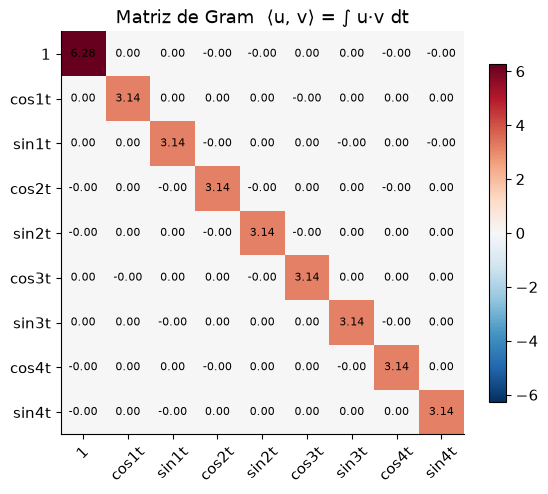

Maior elemento fora da diagonal: 0.0


In [7]:
base, nomes = [np.ones_like(tt)], ["1"]
for k in range(1, 5):
    base += [np.cos(k*tt), np.sin(k*tt)]; nomes += [f"cos{k}t", f"sin{k}t"]
G = np.array([[np.trapezoid(u*v, tt) for v in base] for u in base])

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(G, cmap="RdBu_r", vmin=-2*np.pi, vmax=2*np.pi)
ax.set_xticks(range(len(nomes)), nomes, rotation=45); ax.set_yticks(range(len(nomes)), nomes)
for i in range(len(nomes)):
    for j in range(len(nomes)):
        ax.text(j, i, f"{G[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Matriz de Gram  ⟨u, v⟩ = ∫ u·v dt"); ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8); salvar(fig, "e1_ortogonalidade"); plt.show()
print("Maior elemento fora da diagonal:", np.abs(G - np.diag(np.diag(G))).max().round(10))

**Leitura.** A matriz é **diagonal** ($2\pi$ para a constante, $\pi$ para os demais): as funções são **ortogonais**, como eixos perpendiculares. É isso que permite calcular cada coeficiente **independentemente** por uma projeção, $b_n = \langle f, \sin nt\rangle / \langle \sin nt, \sin nt\rangle$ — exatamente a fórmula usada em 1.1 — e garante que acrescentar um harmônico não "estraga" os coeficientes já calculados. Também vale a identidade de **Parseval**: a energia do sinal é a soma das energias de cada componente, o que justifica medir "quanto de ruído há em cada faixa" na Etapa 2.

---
# Etapa 2 · Do tempo para a frequência (Unidade 3)

## 2.1 O sinal
Usamos um **ECG real** do *MIT-BIH Arrhythmia Database* (PhysioNet, registro 208, derivação MLII), amostrado a **$f_s = 360$ Hz**, em mV. Esse trecho é distribuído pelo próprio SciPy (`scipy.datasets.electrocardiogram`).

O sinal original **já tem** dois problemas reais: deriva lenta da linha de base (respiração e movimento dos eletrodos) e algum ruído muscular. Para tornar o problema completo e controlado, **somamos interferência da rede elétrica** — 60 Hz (rede brasileira) e seu 2º harmônico, 120 Hz — que é o artefato mais comum em eletrocardiografia.

Trabalhamos com uma janela de **60 s** (de 240 s a 300 s do registro), um trecho de ritmo regular.

In [8]:
CSV_ORIGINAL = "dados/ecg_mitbih208_360hz.csv"
fs = 360.0                                      # taxa de amostragem [Hz] — informada pelo PhysioNet

if os.path.exists(CSV_ORIGINAL):
    ecg_registro = np.loadtxt(CSV_ORIGINAL, delimiter=",", skiprows=1, usecols=1)
else:
    try:
        import pooch  # noqa: F401  (o scipy.datasets precisa dele para baixar o arquivo)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pooch"], check=True)
    from scipy.datasets import electrocardiogram
    ecg_registro = electrocardiogram()
    t_reg = np.arange(len(ecg_registro)) / fs
    np.savetxt(CSV_ORIGINAL, np.column_stack([t_reg, ecg_registro]), delimiter=",",
               header="tempo_s,ecg_mV", comments="", fmt=["%.6f", "%.3f"])

print(f"Registro completo: {len(ecg_registro)} amostras = {len(ecg_registro)/fs:.0f} s")

# Janela de análise
t0, dur = 240, 60
ecg = ecg_registro[int(t0*fs): int((t0 + dur)*fs)].copy()
N = len(ecg)
t = np.arange(N) / fs

# Interferência da rede elétrica (60 Hz + 2º harmônico) com fase aleatória
interf = 0.30*np.sin(2*np.pi*60*t + 2*np.pi*np.random.rand()) \
       + 0.10*np.sin(2*np.pi*120*t + 2*np.pi*np.random.rand())
x = ecg + interf                                # <-- sinal de trabalho ("antes")

Ts = 1/fs
print(f"Janela: N = {N} amostras, duração = {N*Ts:.1f} s")
print(f"Período de amostragem Ts = {Ts*1e3:.3f} ms")
print(f"Frequência de Nyquist  fs/2 = {fs/2:.0f} Hz   (maior frequência representável sem aliasing)")
print(f"Resolução em frequência Δf = fs/N = {fs/N:.4f} Hz")

Registro completo: 108000 amostras = 300 s
Janela: N = 21600 amostras, duração = 60.0 s
Período de amostragem Ts = 2.778 ms
Frequência de Nyquist  fs/2 = 180 Hz   (maior frequência representável sem aliasing)
Resolução em frequência Δf = fs/N = 0.0167 Hz


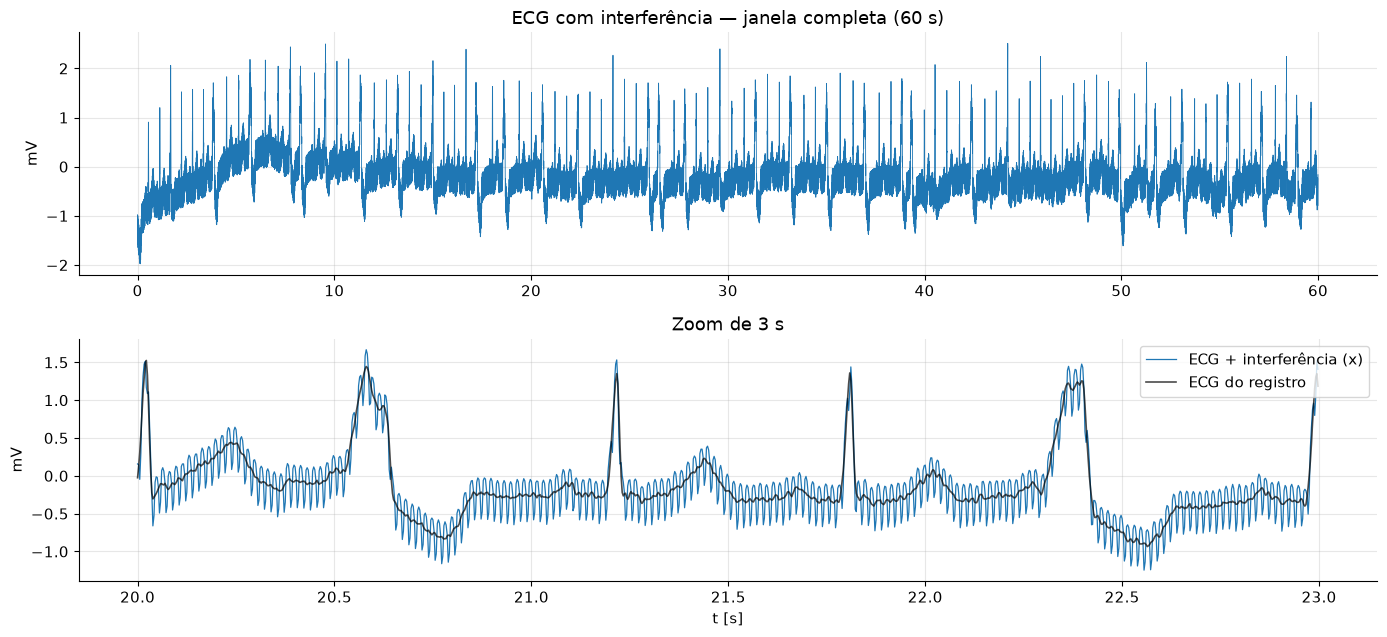

In [9]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(14, 6.5))
a1.plot(t, x, lw=0.6, color="C0")
a1.set_title("ECG com interferência — janela completa (60 s)"); a1.set_ylabel("mV")
z = (t >= 20) & (t < 23)
a2.plot(t[z], x[z], lw=0.9, color="C0", label="ECG + interferência (x)")
a2.plot(t[z], ecg[z], lw=1.2, color="k", alpha=0.7, label="ECG do registro")
a2.set_title("Zoom de 3 s"); a2.set_xlabel("t [s]"); a2.set_ylabel("mV"); a2.legend(loc="upper right")
fig.tight_layout(); salvar(fig, "e2_sinal_tempo"); plt.show()

**Leitura no tempo.** Vemos os batimentos (picos R estreitos), a linha de base "passeando" ao longo dos 60 s e, no zoom, uma faixa espessa de oscilação rápida sobre todo o traçado — a interferência de 60 Hz (60 ciclos por segundo — rápido demais para contar a olho). No tempo os três fenômenos estão **misturados**; vamos separá-los na frequência.

## 2.2 Transformada de Fourier via FFT
Para $N$ amostras $x[k] = x(kT_s)$, a DFT calculada pela FFT é
$$
X[m] = \sum_{k=0}^{N-1} x[k]\,e^{-j2\pi mk/N}, \qquad f_m = m\,\frac{f_s}{N}.
$$
Usamos `rfft` (sinal real ⇒ espectro conjugado-simétrico, basta $0 \le f \le f_s/2$) e a amplitude de um lado $A[m] = 2|X[m]|/N$, que dá diretamente a amplitude em mV de cada senoide.

In [10]:
f = rfftfreq(N, d=1/fs)                          # eixo de frequências [Hz] — depende de fs!
X = rfft(x)
A = 2*np.abs(X)/N; A[0] /= 2                     # amplitude de um lado [mV]

# Frequência cardíaca: maior pico entre 0,7 e 3,5 Hz (42 a 210 bpm)
faixa_fc = (f > 0.7) & (f < 3.5)
f_card = f[faixa_fc][np.argmax(A[faixa_fc])]

# Conferência no domínio do tempo: intervalo médio entre picos R
b_aux, a_aux = signal.butter(2, [5, 30], "bandpass", fs=fs)
r_picos, _ = signal.find_peaks(signal.filtfilt(b_aux, a_aux, ecg), prominence=0.5, distance=int(0.3*fs))
rr = np.diff(r_picos)/fs

print(f"Pico do espectro na faixa cardíaca: {f_card:.3f} Hz  →  {60*f_card:.1f} bpm")
print(f"No tempo: {len(r_picos)} batimentos em {dur} s, RR médio = {rr.mean():.3f} s  →  {60/rr.mean():.1f} bpm")
for fr in [60, 120]:
    i = np.argmin(np.abs(f - fr))
    print(f"Amplitude em {fr} Hz: {A[i]:.3f} mV")

Pico do espectro na faixa cardíaca: 1.633 Hz  →  98.0 bpm
No tempo: 99 batimentos em 60 s, RR médio = 0.603 s  →  99.5 bpm
Amplitude em 60 Hz: 0.300 mV
Amplitude em 120 Hz: 0.100 mV


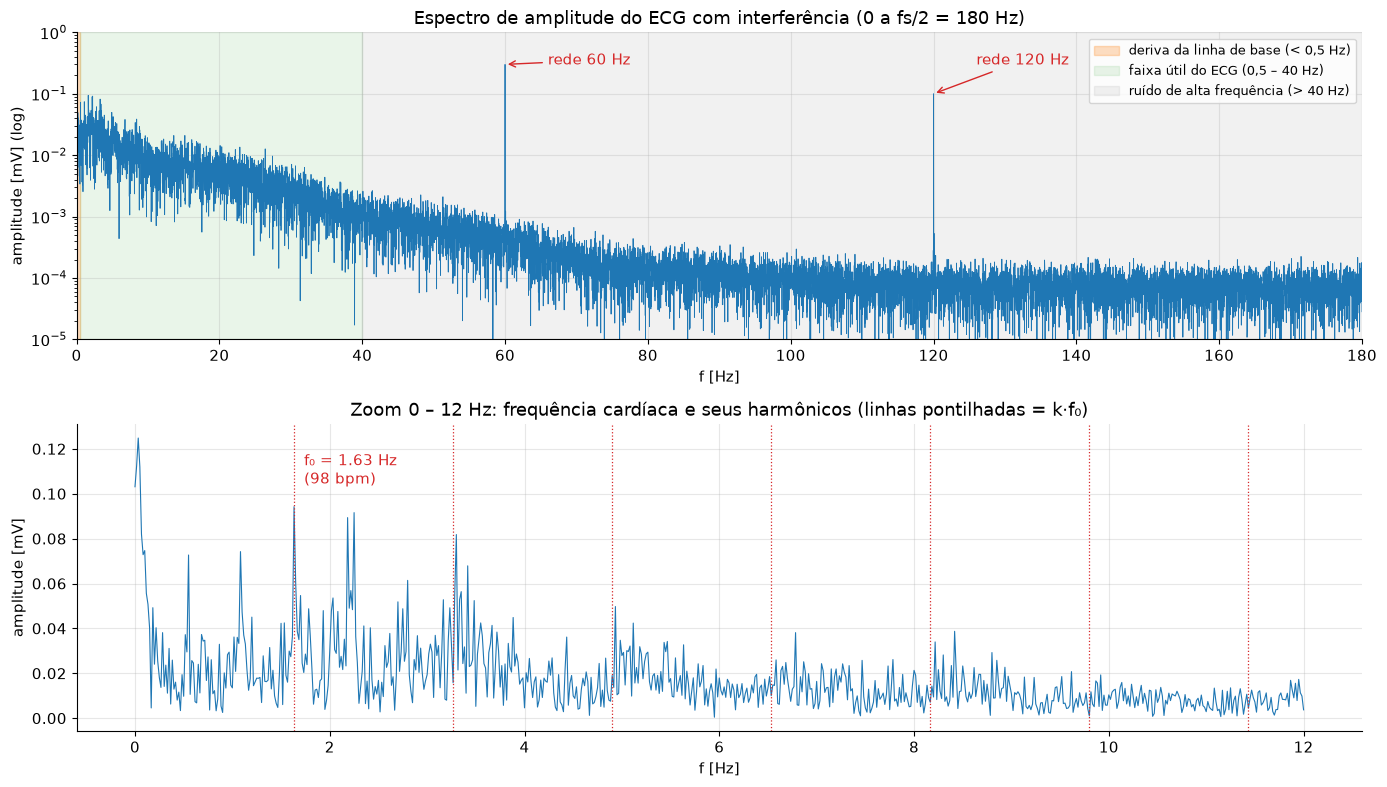

In [11]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(14, 8))
a1.semilogy(f, A, lw=0.6)
a1.set_xlim(0, fs/2); a1.set_ylim(1e-5, 1)
a1.set_title(f"Espectro de amplitude do ECG com interferência (0 a fs/2 = {fs/2:.0f} Hz)")
a1.set_xlabel("f [Hz]"); a1.set_ylabel("amplitude [mV] (log)")
a1.axvspan(0, 0.5, color="C1", alpha=0.25, label="deriva da linha de base (< 0,5 Hz)")
a1.axvspan(0.5, 40, color="C2", alpha=0.10, label="faixa útil do ECG (0,5 – 40 Hz)")
a1.axvspan(40, fs/2, color="C7", alpha=0.10, label="ruído de alta frequência (> 40 Hz)")
for fr in [60, 120]:
    a1.annotate(f"rede {fr} Hz", xy=(fr, A[np.argmin(abs(f-fr))]), xytext=(fr + 6, 0.3),
                arrowprops=dict(arrowstyle="->", color="C3"), color="C3")
a1.legend(loc="upper right", fontsize=9)

z = f <= 12
a2.plot(f[z], A[z], lw=0.8)
for h in range(1, 8):
    a2.axvline(h*f_card, color="C3", ls=":", lw=0.9)
a2.text(f_card, A[z].max()*0.95, f"  f₀ = {f_card:.2f} Hz\n  ({60*f_card:.0f} bpm)", color="C3", va="top")
a2.set_title("Zoom 0 – 12 Hz: frequência cardíaca e seus harmônicos (linhas pontilhadas = k·f₀)")
a2.set_xlabel("f [Hz]"); a2.set_ylabel("amplitude [mV]")
fig.tight_layout(); salvar(fig, "e2_espectro"); plt.show()

In [12]:
def energia_por_faixa(Xc, f):
    # Fração da energia (Parseval) em cada faixa de interesse
    E = np.abs(Xc)**2; E[1:] *= 2; E_tot = E[1:].sum()   # ignora a média (f = 0)
    faixas = {"deriva  (0 – 0,5 Hz)": (1e-9, 0.5), "ECG útil (0,5 – 40 Hz)": (0.5, 40),
              "transição (40 – 59 Hz)": (40, 59), "rede     (59 – 61 Hz)": (59, 61),
              "alta (61 – 180 Hz, s/ 120)": None, "rede     (119 – 121 Hz)": (119, 121)}
    res = {}
    for nome, lim in faixas.items():
        if lim is None:
            m = (f >= 61) & ~((f >= 119) & (f < 121))
        else:
            m = (f >= lim[0]) & (f < lim[1])
        res[nome] = E[m].sum()
    return res, E_tot

res_antes, Etot_antes = energia_por_faixa(X, f)
for k, v in res_antes.items():
    print(f"{k:27s}: {100*v/Etot_antes:6.2f} % da energia")

deriva  (0 – 0,5 Hz)       :  14.49 % da energia
ECG útil (0,5 – 40 Hz)     :  66.26 % da energia
transição (40 – 59 Hz)     :   0.16 % da energia
rede     (59 – 61 Hz)      :  17.16 % da energia
alta (61 – 180 Hz, s/ 120) :   0.03 % da energia
rede     (119 – 121 Hz)    :   1.89 % da energia


**Leitura do espectro (ligando tempo ↔ frequência).**

* **Frequência cardíaca.** O maior pico na faixa 0,7–3,5 Hz é a **frequência fundamental do batimento**, e há picos próximos de seus múltiplos $k f_0$ (linhas pontilhadas) — o ECG é *quase* periódico, então o espectro é *quase* um espectro de linhas, como o da onda quadrada da Etapa 1. As linhas não são perfeitamente nítidas porque o intervalo entre batimentos varia um pouco (e este registro tem extrassístoles), o que espalha a energia ao redor de cada harmônico. A frequência obtida no espectro bate com a contagem dos picos R no tempo (valores impressos acima).
* **Deriva da linha de base** (respiração/movimento): energia concentrada **abaixo de 0,5 Hz**. Corresponde à "onda lenta" que levanta e abaixa o traçado inteiro no gráfico de 60 s. Carrega uma fração grande da energia (tabela acima), apesar de não ter informação cardíaca.
* **Conteúdo útil do ECG**: entre ≈ 0,5 Hz (ondas P e T, lentas) e ≈ 40 Hz (o QRS, rápido e estreito, precisa de harmônicos altos — lembre-se da Etapa 1: bordas rápidas = frequências altas).
* **Rede elétrica**: duas **linhas espectrais isoladas** em 60 e 120 Hz. No tempo eram uma "névoa" sobre o traçado; na frequência são dois picos de largura de 1 bin — um ruído senoidal puro é o caso mais fácil de enxergar no espectro.
* **Acima de 40 Hz**: piso de ruído de banda larga (ruído muscular e de quantização), muito abaixo do sinal.

## 2.3 Taxa de amostragem, Nyquist e *aliasing*
Com $f_s = 360$ Hz, o limite de Nyquist é 180 Hz: tudo o que vimos (inclusive 120 Hz) está abaixo dele e aparece no lugar certo. O que aconteceria se reamostrássemos o sinal a $f_s' = 90$ Hz (Nyquist = 45 Hz) **sem** filtro anti-aliasing?

Nova fs = 90 Hz, Nyquist = 45 Hz
60 Hz  aparece em |60 − 1·90|  = 30 Hz
120 Hz aparece em |120 − 1·90| = 30 Hz
Amplitude em 30 Hz — sem anti-aliasing: 0.359 mV | com anti-aliasing: 0.0020 mV


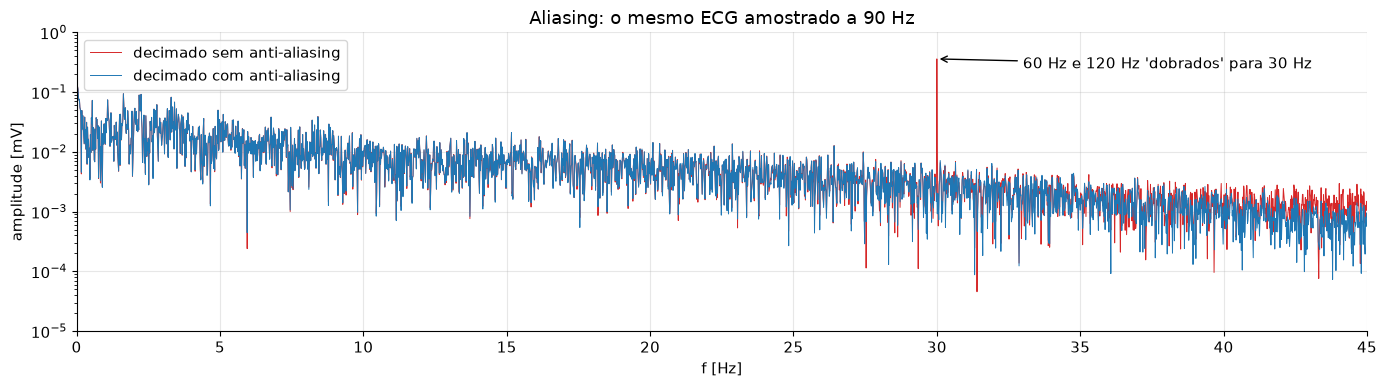

In [13]:
fator = 4
fs2 = fs/fator
x_sem_aa = x[::fator]                                      # só descarta amostras
x_com_aa = signal.decimate(x, fator, ftype="fir", zero_phase=True)   # filtra antes de descartar
f2 = rfftfreq(len(x_sem_aa), 1/fs2)
A_sem = 2*np.abs(rfft(x_sem_aa))/len(x_sem_aa)
A_com = 2*np.abs(rfft(x_com_aa))/len(x_com_aa)

alias = lambda fr: abs(fr - fs2*round(fr/fs2))             # frequência aparente após amostrar a fs2
print(f"Nova fs = {fs2:.0f} Hz, Nyquist = {fs2/2:.0f} Hz")
print(f"60 Hz  aparece em |60 − 1·90|  = {alias(60):.0f} Hz")
print(f"120 Hz aparece em |120 − 1·90| = {alias(120):.0f} Hz")
i30 = np.argmin(abs(f2 - 30))
print(f"Amplitude em 30 Hz — sem anti-aliasing: {A_sem[i30]:.3f} mV | com anti-aliasing: {A_com[i30]:.4f} mV")

fig, ax = plt.subplots(figsize=(14, 4))
ax.semilogy(f2, A_sem, lw=0.7, color="C3", label="decimado sem anti-aliasing")
ax.semilogy(f2, A_com, lw=0.7, color="C0", label="decimado com anti-aliasing")
ax.annotate("60 Hz e 120 Hz 'dobrados' para 30 Hz", xy=(30, A_sem[i30]), xytext=(33, 0.25),
            arrowprops=dict(arrowstyle="->"))
ax.set_xlim(0, fs2/2); ax.set_ylim(1e-5, 1)
ax.set_title(f"Aliasing: o mesmo ECG amostrado a {fs2:.0f} Hz"); ax.set_xlabel("f [Hz]"); ax.set_ylabel("amplitude [mV]")
ax.legend(); fig.tight_layout(); salvar(fig, "e2_aliasing"); plt.show()

**Leitura (Nyquist).** Amostrando a 90 Hz, as componentes de 60 e 120 Hz estão acima do novo limite de 45 Hz e são **"dobradas"** para $|60-90| = |120-90| = 30$ Hz — elas caem **dentro** da faixa útil do ECG, onde nenhum filtro posterior consegue distingui-las do sinal verdadeiro. Com o filtro anti-aliasing (passa-baixas antes de descartar amostras) o pico desaparece. Lição: **a taxa de amostragem define o eixo de frequências** e o que é recuperável; sem conhecer $f_s$, o espectro não teria unidade nenhuma.

---
# Etapa 3 · Filtrar e reconstruir (Unidade 3)

## 3.1 Projeto do filtro
Cada problema identificado no espectro recebe um bloco, e o filtro final é a **cascata** (produto) dos três:

| Problema (Etapa 2) | Bloco | Justificativa |
|---|---|---|
| Deriva < 0,5 Hz | **Passa-altas Butterworth, 2ª ordem, $f_c = 0{,}5$ Hz** | remove a linha de base sem apagar as ondas P/T (que estão acima de ~0,7 Hz) |
| Ruído > 40 Hz e 120 Hz | **Passa-baixas Butterworth, 4ª ordem, $f_c = 40$ Hz** | preserva o QRS (energia até ~40 Hz); 120 Hz cai a −38 dB |
| Rede 60 Hz | **Notch (rejeita-faixa estreito) em 60 Hz, $Q = 30$** | o passa-baixas sozinho atenua 60 Hz só ≈ 14 dB; o notch zera exatamente essa linha |

Escolhemos **Butterworth** porque tem resposta **maximamente plana** na banda passante (não distorce a amplitude do ECG) e transição suave (evita o *ringing* tipo Gibbs da Etapa 1). O filtro é definido como **sistema analógico** — $H(s)$ — e estudado em detalhe na Etapa 4.

In [14]:
fc_hp, fc_lp, f_notch, Q = 0.5, 40.0, 60.0, 30.0
w_hp, w_lp, w0 = 2*np.pi*fc_hp, 2*np.pi*fc_lp, 2*np.pi*f_notch   # [rad/s]

# Blocos no formato zeros/polos/ganho (z, p, k), analógicos (variável s)
z_hp, p_hp, k_hp = signal.butter(2, w_hp, "highpass", analog=True, output="zpk")
z_lp, p_lp, k_lp = signal.butter(4, w_lp, "lowpass",  analog=True, output="zpk")
z_n = np.array([1j*w0, -1j*w0])                         # zeros sobre o eixo jω  → nulo em 60 Hz
p_n = np.roots([1, w0/Q, w0**2])                        # polos de s² + (ω0/Q)s + ω0²
k_n = 1.0

# Filtro total = produto das funções de transferência = união de zeros e polos, produto dos ganhos
z_tot = np.concatenate([z_hp, z_lp, z_n])
p_tot = np.concatenate([p_hp, p_lp, p_n])
k_tot = k_hp * k_lp * k_n

def H_de_f(freqs_hz, z=z_tot, p=p_tot, k=k_tot):
    # Avalia H(s) em s = j2πf
    _, h = signal.freqs_zpk(z, p, k, worN=2*np.pi*np.asarray(freqs_hz))
    return h

for fr in [0.1, 0.5, 1.0, 10, 40, 60, 120]:
    g = abs(H_de_f([fr])[0])
    db = f"{20*np.log10(g):7.1f} dB" if g > 1e-9 else "   −∞ dB (zero exato)"
    print(f"|H| em {fr:6.1f} Hz = {g:.4f}  ({db})")

|H| em    0.1 Hz = 0.0400  (  -28.0 dB)
|H| em    0.5 Hz = 0.7071  (   -3.0 dB)
|H| em    1.0 Hz = 0.9701  (   -0.3 dB)
|H| em   10.0 Hz = 1.0000  (   -0.0 dB)
|H| em   40.0 Hz = 0.7065  (   -3.0 dB)
|H| em   60.0 Hz = 0.0000  (   −∞ dB (zero exato))
|H| em  120.0 Hz = 0.0123  (  -38.2 dB)


## 3.2 Filtragem no domínio da frequência e reconstrução pela Transformada Inversa
O teorema da convolução diz que filtrar no tempo ($y = h * x$) equivale a **multiplicar** na frequência:
$$
Y(f) = H(f)\,X(f) \quad\Longrightarrow\quad y(t) = \mathcal{F}^{-1}\{H(f)\,X(f)\}.
$$
Procedimento:
1. espelhar 5 s em cada extremidade (a FFT supõe o sinal periódico; o espelhamento evita um "salto" artificial entre o fim e o início — a mesma descontinuidade que gera Gibbs);
2. `rfft` → multiplicar cada bin por $|H(j2\pi f)|$ → `irfft` (**FFT inversa**);
3. descartar o espelhamento.

Usamos o **módulo** $|H|$ (fase zero): como o processamento é *offline*, podemos evitar o atraso/distorção de fase de um filtro causal, o que preserva a posição e a forma do QRS e do segmento ST — importante em diagnóstico.

In [15]:
def filtrar_fft(sinal, fs, H_func, pad_s=5.0):
    npad = int(pad_s*fs)
    xp = np.pad(sinal - sinal.mean(), npad, mode="reflect")
    Xp = rfft(xp)
    fp = rfftfreq(len(xp), 1/fs)
    Yp = Xp * np.abs(H_func(fp))           # Y = |H|·X  (fase zero)
    yp = irfft(Yp, n=len(xp))              # Transformada de Fourier Inversa
    return yp[npad:-npad]

y = filtrar_fft(x, fs, H_de_f)              # <-- sinal filtrado ("depois")

# Para COMPARAR espectros antes/depois usamos a janela de Hann: cortar o sinal em 60 s cria
# um salto entre o fim e o início (a FFT o trata como periódico), e esse salto "vaza" energia
# para todas as frequências — mascarando o quanto o filtro realmente atenuou.
janela = np.hanning(N)
Xw = rfft((x - x.mean())*janela);  Aw_x = 2*np.abs(Xw)/janela.sum()
Yw = rfft(y*janela);               Aw_y = 2*np.abs(Yw)/janela.sum()

# Verificação da reconstrução: FFT → IFFT sem filtro devolve o sinal original?
print("Erro FFT→IFFT sem filtro:", np.max(np.abs(irfft(rfft(x), n=N) - x)).round(15))

np.savetxt("dados/ecg_filtrado.csv", np.column_stack([t + t0, x, y]), delimiter=",",
           header="tempo_s,ecg_com_interferencia_mV,ecg_filtrado_mV", comments="", fmt="%.6f")
print("Salvo: dados/ecg_filtrado.csv")

Erro FFT→IFFT sem filtro: 1e-15
Salvo: dados/ecg_filtrado.csv


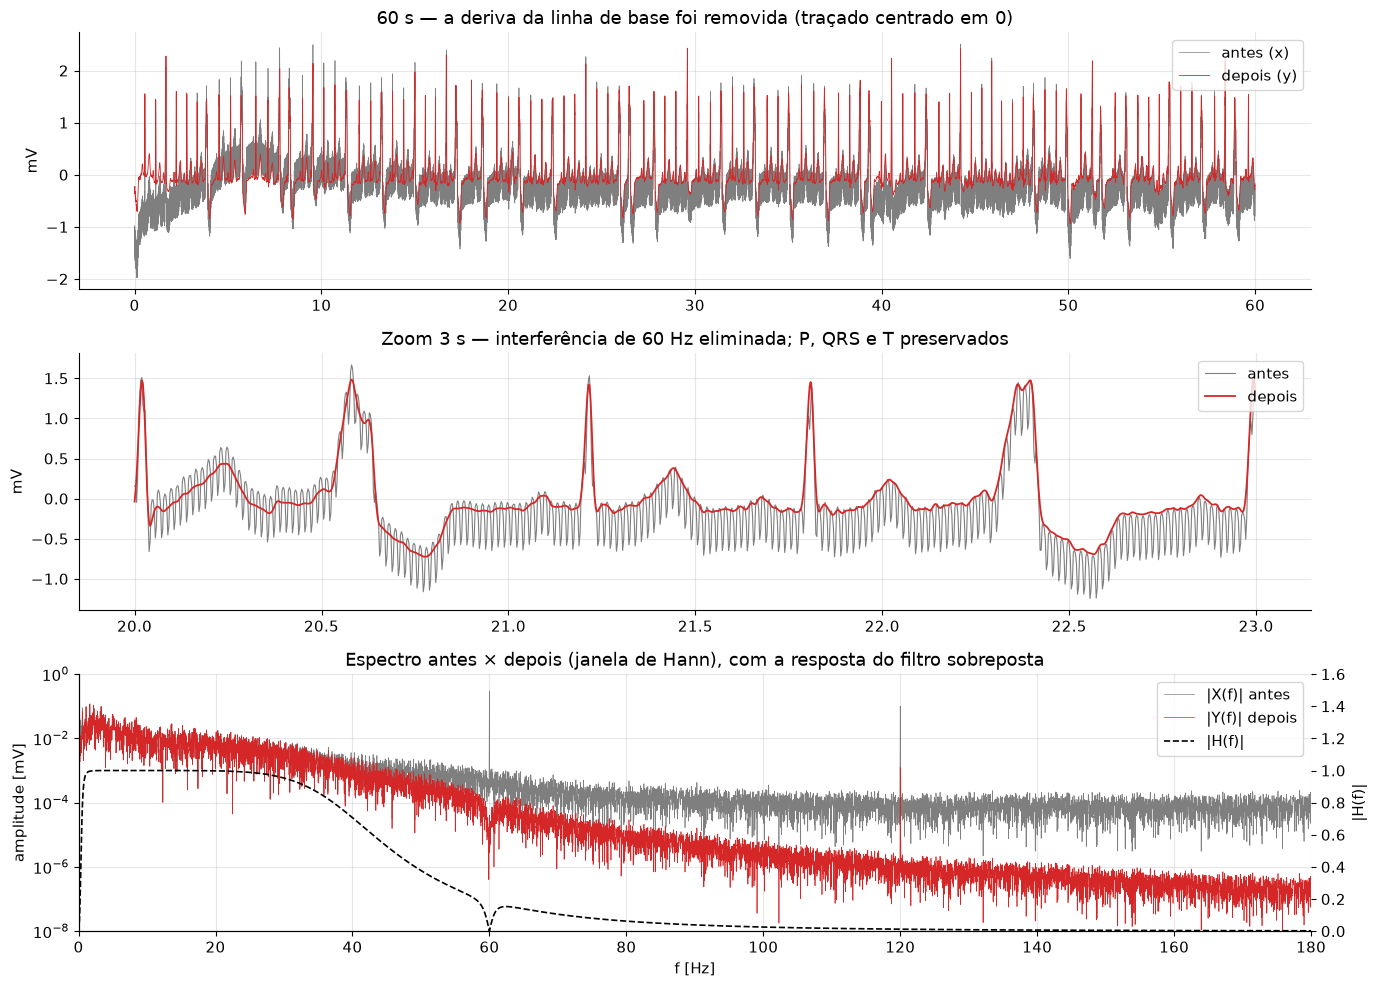

In [16]:
fig, axs = plt.subplots(3, 1, figsize=(14, 10))
axs[0].plot(t, x, lw=0.5, color="C7", label="antes (x)")
axs[0].plot(t, y, lw=0.6, color="C3", label="depois (y)")
axs[0].set_title("60 s — a deriva da linha de base foi removida (traçado centrado em 0)")
axs[0].set_ylabel("mV"); axs[0].legend(loc="upper right")

z = (t >= 20) & (t < 23)
axs[1].plot(t[z], x[z], lw=0.8, color="C7", label="antes")
axs[1].plot(t[z], y[z], lw=1.3, color="C3", label="depois")
axs[1].set_title("Zoom 3 s — interferência de 60 Hz eliminada; P, QRS e T preservados")
axs[1].set_ylabel("mV"); axs[1].legend(loc="upper right")

axs[2].semilogy(f, Aw_x, lw=0.5, color="C7", label="|X(f)| antes")
axs[2].semilogy(f, Aw_y, lw=0.5, color="C3", label="|Y(f)| depois")
axs[2].set_ylim(1e-8, 1); axs[2].set_xlim(0, fs/2)
ax_h = axs[2].twinx()
fh = np.linspace(0.01, fs/2, 20000)
ax_h.plot(fh, np.abs(H_de_f(fh)), "k--", lw=1.2, label="|H(f)|"); ax_h.set_ylim(0, 1.6)
ax_h.set_ylabel("|H(f)|"); ax_h.grid(False)
axs[2].set_title("Espectro antes × depois (janela de Hann), com a resposta do filtro sobreposta")
axs[2].set_xlabel("f [Hz]"); axs[2].set_ylabel("amplitude [mV]")
h1, l1 = axs[2].get_legend_handles_labels(); h2, l2 = ax_h.get_legend_handles_labels()
axs[2].legend(h1 + h2, l1 + l2, loc="upper right")
fig.tight_layout(); salvar(fig, "e3_antes_depois"); plt.show()

In [17]:
res_x, Etot_x = energia_por_faixa(Xw, f)
res_y, _ = energia_por_faixa(Yw, f)
print("Energia de cada faixa, em % da energia TOTAL do sinal antes do filtro (espectros com janela de Hann)")
print(f"{'faixa':27s} | {'antes':>8s} | {'depois':>8s} | atenuação")
for k in res_x:
    a, d = res_x[k], res_y[k]
    print(f"{k:27s} | {100*a/Etot_x:7.2f}% | {100*d/Etot_x:7.3f}% | {10*np.log10(d/a):6.1f} dB")

# A faixa útil foi preservada? Compara x e y depois de ambos passarem por um passa-faixa estreito 5–30 Hz
sos_ref = signal.butter(4, [5, 30], "bandpass", fs=fs, output="sos")
corr = np.corrcoef(signal.sosfiltfilt(sos_ref, ecg), signal.sosfiltfilt(sos_ref, y))[0, 1]
print(f"\nCorrelação do QRS (faixa 5–30 Hz) entre o ECG original e o filtrado: {corr:.4f}")
R_orig = signal.sosfiltfilt(signal.butter(2, 0.5, "highpass", fs=fs, output="sos"), ecg)[r_picos].mean()
R_filt = y[r_picos].mean()
print(f"Amplitude média dos picos R — original (só sem deriva): {R_orig:.3f} mV | filtrado: {R_filt:.3f} mV "
      f"({100*(R_filt/R_orig - 1):+.1f}%)")

Energia de cada faixa, em % da energia TOTAL do sinal antes do filtro (espectros com janela de Hann)
faixa                       |    antes |   depois | atenuação
deriva  (0 – 0,5 Hz)        |    4.19% |   0.184% |  -13.6 dB
ECG útil (0,5 – 40 Hz)      |   75.31% |  73.928% |   -0.1 dB
transição (40 – 59 Hz)      |    0.18% |   0.046% |   -5.9 dB
rede     (59 – 61 Hz)       |   18.15% |   0.000% |  -56.0 dB
alta (61 – 180 Hz, s/ 120)  |    0.02% |   0.000% |  -20.0 dB
rede     (119 – 121 Hz)     |    2.14% |   0.000% |  -38.2 dB

Correlação do QRS (faixa 5–30 Hz) entre o ECG original e o filtrado: 0.9999
Amplitude média dos picos R — original (só sem deriva): 1.648 mV | filtrado: 1.626 mV (-1.3%)


## 3.3 Verificação cruzada: o mesmo filtro em versão digital
Para confirmar que a filtragem por FFT está correta, aplicamos o **mesmo projeto** como filtro digital IIR (Butterworth + notch via `scipy.signal`, aplicado ida-e-volta com `sosfiltfilt`, também fase zero) e comparamos.

In [18]:
sos_dig = np.vstack([signal.butter(1, fc_hp, "highpass", fs=fs, output="sos"),   # 1ª ordem ×2 (ida e volta) ≈ 2ª ordem
                     signal.butter(2, fc_lp, "lowpass",  fs=fs, output="sos"),   # 2ª ordem ×2 ≈ 4ª ordem
                     signal.tf2sos(*signal.iirnotch(f_notch, Q, fs=fs))])
y_dig = signal.sosfiltfilt(sos_dig, x - x.mean())
m = (t > 5) & (t < dur - 5)                                   # ignora bordas
print(f"Correlação FFT × IIR digital: {np.corrcoef(y[m], y_dig[m])[0, 1]:.5f}")
print(f"Diferença RMS: {np.sqrt(np.mean((y[m]-y_dig[m])**2))*1e3:.2f} µV  (sinal RMS: {np.sqrt(np.mean(y[m]**2))*1e3:.0f} µV)")

Correlação FFT × IIR digital: 0.99805
Diferença RMS: 31.84 µV  (sinal RMS: 414 µV)


**Leitura (antes × depois).**

* **No tempo:** o traçado filtrado fica centrado em zero (deriva removida pelo passa-altas) e a "névoa" de 60 Hz some (notch); os batimentos mantêm a forma — P, QRS e T continuam nos mesmos instantes, porque usamos fase zero.
* **Na frequência:** o espectro "depois" é o "antes" multiplicado pela curva tracejada $|H(f)|$: igual na faixa 0,5–40 Hz, com um **vale profundo em 60 Hz**, a linha de 120 Hz e o piso acima de 61 Hz derrubados e a região < 0,5 Hz atenuada. Na faixa de transição 40–59 Hz a atenuação é menor: o Butterworth corta de forma suave, de propósito (Etapa 1: corte abrupto ⇒ *ringing*).
* **Números:** a tabela mostra a atenuação em cada faixa; a faixa útil quase não muda enquanto a rede cai dezenas de dB. A correlação do QRS original × filtrado próxima de 1 indica que **o filtro removeu o ruído sem destruir a informação clínica**. O pico R fica levemente mais baixo (≈ 1 %, valor impresso acima): o passa-baixas corta parte dos harmônicos acima de 40 Hz que formam a ponta do QRS — exatamente o efeito de "menos termos na série" da Etapa 1. É o preço de remover o ruído; subir $f_c$ preservaria mais o pico e deixaria passar mais ruído. A versão digital independente dá praticamente o mesmo resultado, validando a implementação por FFT inversa.
* **Limite do método:** o filtro não separa o que está na **mesma faixa** do sinal — o ruído muscular entre 0,5 e 40 Hz continua lá. Para isso seriam necessárias técnicas adaptativas (fora do escopo).

---
# Etapa 4 · O filtro como sistema linear (Unidade 4)

## 4.1 Aquecimento: filtro RC de 1ª ordem
Circuito RC série com saída no capacitor: pela lei das malhas, $RC\,\dfrac{dy}{dt} + y(t) = x(t)$.
Aplicando Laplace com condição inicial nula ($\mathcal{L}\{y'\} = sY(s)$):
$$
RC\,s\,Y(s) + Y(s) = X(s) \quad\Longrightarrow\quad H(s) = \frac{Y(s)}{X(s)} = \frac{1}{1 + sRC}
$$

In [19]:
s = sp.symbols("s")
tt_s = sp.symbols("t", positive=True)
R, C = sp.symbols("R C", positive=True)

H_rc = 1/(1 + s*R*C)
polo_rc = sp.solve(sp.denom(H_rc), s)
h_rc = sp.inverse_laplace_transform(H_rc, s, tt_s)                # resposta ao impulso
deg_rc = sp.simplify(sp.inverse_laplace_transform(H_rc/s, s, tt_s))  # resposta ao degrau: H(s)·(1/s)

print("H(s) =", H_rc)
print("polo: s =", polo_rc)
print("h(t) = L⁻¹{H(s)} =", h_rc)
print("resposta ao degrau =", deg_rc)

# Exemplo numérico: RC com a mesma frequência de corte do nosso passa-baixas (40 Hz)
Rv = 1e3
Cv = 1/(2*np.pi*fc_lp*Rv)
print(f"\nPara fc = {fc_lp:.0f} Hz com R = 1 kΩ: C = {Cv*1e6:.2f} µF; polo em s = −1/RC = {-1/(Rv*Cv):.1f} rad/s")
H_rc_jw = lambda fr: 1/(1 + 1j*2*np.pi*fr*Rv*Cv)
print(f"|H(j2π·40)| = {abs(H_rc_jw(40)):.4f} = 1/√2 → −3 dB exatamente na frequência do polo")
print(f"|H(j2π·60)| = {abs(H_rc_jw(60)):.3f} → o RC sozinho deixaria passar {abs(H_rc_jw(60))*100:.0f}% do ruído de 60 Hz")

H(s) = 1/(C*R*s + 1)
polo: s = [-1/(C*R)]
h(t) = L⁻¹{H(s)} = exp(-t/(C*R))/(C*R)
resposta ao degrau = 1 - exp(-t/(C*R))

Para fc = 40 Hz com R = 1 kΩ: C = 3.98 µF; polo em s = −1/RC = -251.3 rad/s
|H(j2π·40)| = 0.7071 = 1/√2 → −3 dB exatamente na frequência do polo
|H(j2π·60)| = 0.555 → o RC sozinho deixaria passar 55% do ruído de 60 Hz


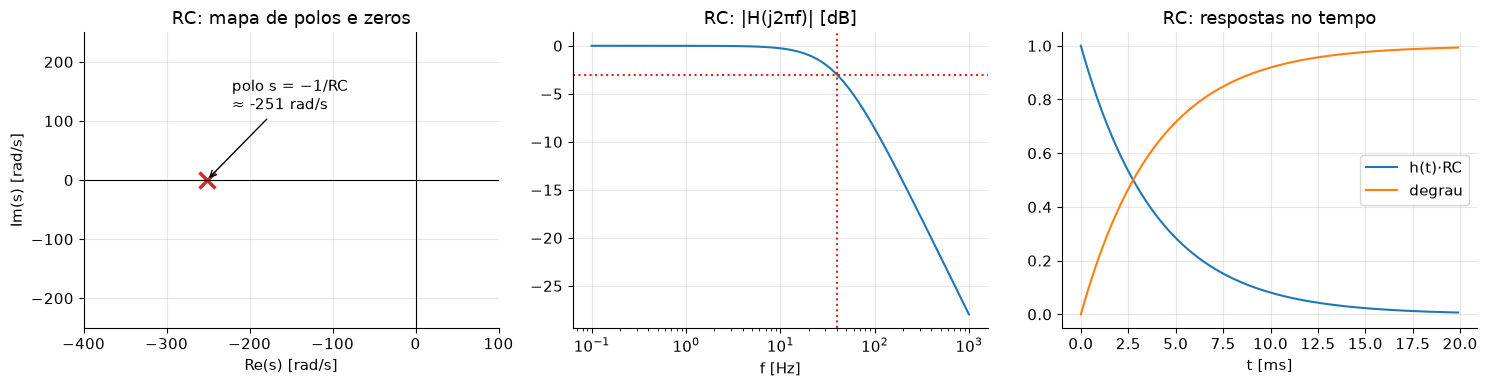

In [20]:
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(15, 4))
p_rc = -1/(Rv*Cv)
a1.plot([p_rc], [0], "x", ms=12, mew=2.5, color="C3")
a1.axhline(0, color="k", lw=0.8); a1.axvline(0, color="k", lw=0.8)
a1.set_xlim(-400, 100); a1.set_ylim(-250, 250)
a1.set_title("RC: mapa de polos e zeros"); a1.set_xlabel("Re(s) [rad/s]"); a1.set_ylabel("Im(s) [rad/s]")
a1.annotate(f"polo s = −1/RC\n≈ {p_rc:.0f} rad/s", xy=(p_rc, 0), xytext=(p_rc + 30, 120), arrowprops=dict(arrowstyle="->"))
fr = np.logspace(-1, 3, 500)
a2.semilogx(fr, 20*np.log10(abs(H_rc_jw(fr)))); a2.axvline(fc_lp, color="C3", ls=":")
a2.axhline(-3, color="C3", ls=":"); a2.set_title("RC: |H(j2πf)| [dB]"); a2.set_xlabel("f [Hz]")
tr = np.linspace(0, 5*Rv*Cv, 400)
a3.plot(tr*1e3, (1/(Rv*Cv))*np.exp(-tr/(Rv*Cv))/(1/(Rv*Cv)), label="h(t)·RC")
a3.plot(tr*1e3, 1 - np.exp(-tr/(Rv*Cv)), label="degrau")
a3.set_title("RC: respostas no tempo"); a3.set_xlabel("t [ms]"); a3.legend()
fig.tight_layout(); salvar(fig, "e4_rc"); plt.show()

**Leitura (RC).** Um único polo real negativo em $s = -1/RC$. Como ele está no semiplano esquerdo, a resposta ao impulso $h(t) = \frac{1}{RC}e^{-t/RC}$ **decai** ⇒ sistema **estável**. A frequência de −3 dB é a **distância do polo à origem**, $\omega_c = 1/RC$. O RC é o "átomo" dos filtros — mas, com uma queda de só 20 dB/década, ele deixaria passar ~55 % do ruído de 60 Hz. Por isso nosso filtro usa mais polos.

## 4.2 A função de transferência do filtro da Etapa 3
$$
H(s) = \underbrace{\frac{s^2}{s^2 + \sqrt2\,\omega_{hp}\,s + \omega_{hp}^2}}_{\text{passa-altas (2ª ordem)}}
\cdot \underbrace{\frac{\omega_{lp}^4}{B_4(s)}}_{\text{passa-baixas (4ª ordem)}}
\cdot \underbrace{\frac{s^2 + \omega_0^2}{s^2 + \frac{\omega_0}{Q}s + \omega_0^2}}_{\text{notch 60 Hz}}
$$
com $\omega_{hp} = 2\pi\cdot0{,}5$, $\omega_{lp} = 2\pi\cdot40$, $\omega_0 = 2\pi\cdot60$ rad/s e $B_4$ o polinômio de Butterworth de 4ª ordem. Vamos montá-la simbolicamente a partir dos zeros e polos calculados na Etapa 3:

In [21]:
def bloco_sympy(z, p, k, dig=4):
    # Monta k·Π(s − z)/Π(s − p) e expande numerador/denominador com coeficientes reais
    num = sp.Float(k, dig) * sp.prod([(s - sp.nsimplify(complex(zi).real) - sp.I*sp.nsimplify(complex(zi).imag)) for zi in z]) if len(z) else sp.Float(k, dig)
    den = sp.prod([(s - complex(pi).real - sp.I*complex(pi).imag) for pi in p])
    num, den = sp.expand(num), sp.expand(den)
    num = sp.Poly(num, s); den = sp.Poly(den, s)
    arred = lambda P: sum(sp.Float(sp.re(c), dig)*s**(P.degree() - i) for i, c in enumerate(P.all_coeffs()))
    return arred(num) / arred(den)

H_hp_s = bloco_sympy(z_hp, p_hp, k_hp)
H_lp_s = bloco_sympy(z_lp, p_lp, k_lp)
H_n_s  = bloco_sympy(z_n,  p_n,  k_n)
display(sp.Eq(sp.Symbol("H_{PA}(s)"), H_hp_s))
display(sp.Eq(sp.Symbol("H_{PB}(s)"), H_lp_s))
display(sp.Eq(sp.Symbol("H_{N}(s)"),  H_n_s))
print(f"Ordem total do sistema: {len(p_tot)} polos, {len(z_tot)} zeros")

Eq(H_{PA}(s), 1.0*s**2/(1.0*s**2 + 4.443*s + 9.87))

Eq(H_{PB}(s), 3.99e+9/(1.0*s**4 + 656.8*s**3 + 2.157e+5*s**2 + 4.148e+7*s + 3.99e+9))

Eq(H_{N}(s), (1.0*s**2 + 1.421e+5)/(1.0*s**2 + 12.57*s + 1.421e+5))

Ordem total do sistema: 8 polos, 4 zeros


In [22]:
print(f"{'tipo':5s} {'bloco':12s} {'valor de s [rad/s]':>28s} {'|s|/2π [Hz]':>12s} {'ζ (amortec.)':>13s}")
linhas = []
for nome, zs, ps in [("passa-altas", z_hp, p_hp), ("passa-baixas", z_lp, p_lp), ("notch", z_n, p_n)]:
    for zi in zs:
        linhas.append(("zero", nome, zi))
    for pi in ps:
        linhas.append(("polo", nome, pi))
for tipo, nome, v in linhas:
    zeta = -v.real/abs(v) if (tipo == "polo") else float("nan")
    print(f"{tipo:5s} {nome:12s} {v.real:+12.3f} {v.imag:+12.3f}j   {abs(v)/(2*np.pi):12.3f} {zeta:13.4f}")

estavel = np.all(p_tot.real < 0)
print(f"\nMaior parte real entre os polos: {p_tot.real.max():.4f} rad/s")
print("ESTÁVEL ✔ — todos os polos no semiplano esquerdo (Re(s) < 0)" if estavel else "INSTÁVEL ✘")

tipo  bloco                  valor de s [rad/s]  |s|/2π [Hz]  ζ (amortec.)
zero  passa-altas        +0.000       +0.000j          0.000           nan
zero  passa-altas        +0.000       +0.000j          0.000           nan
polo  passa-altas        -2.221       -2.221j          0.500        0.7071
polo  passa-altas        -2.221       +2.221j          0.500        0.7071
polo  passa-baixas      -96.179     +232.196j         40.000        0.3827
polo  passa-baixas     -232.196      +96.179j         40.000        0.9239
polo  passa-baixas     -232.196      -96.179j         40.000        0.9239
polo  passa-baixas      -96.179     -232.196j         40.000        0.3827
zero  notch              +0.000     +376.991j         60.000           nan
zero  notch              -0.000     -376.991j         60.000           nan
polo  notch              -6.283     +376.939j         60.000        0.0167
polo  notch              -6.283     -376.939j         60.000        0.0167

Maior parte real entre o

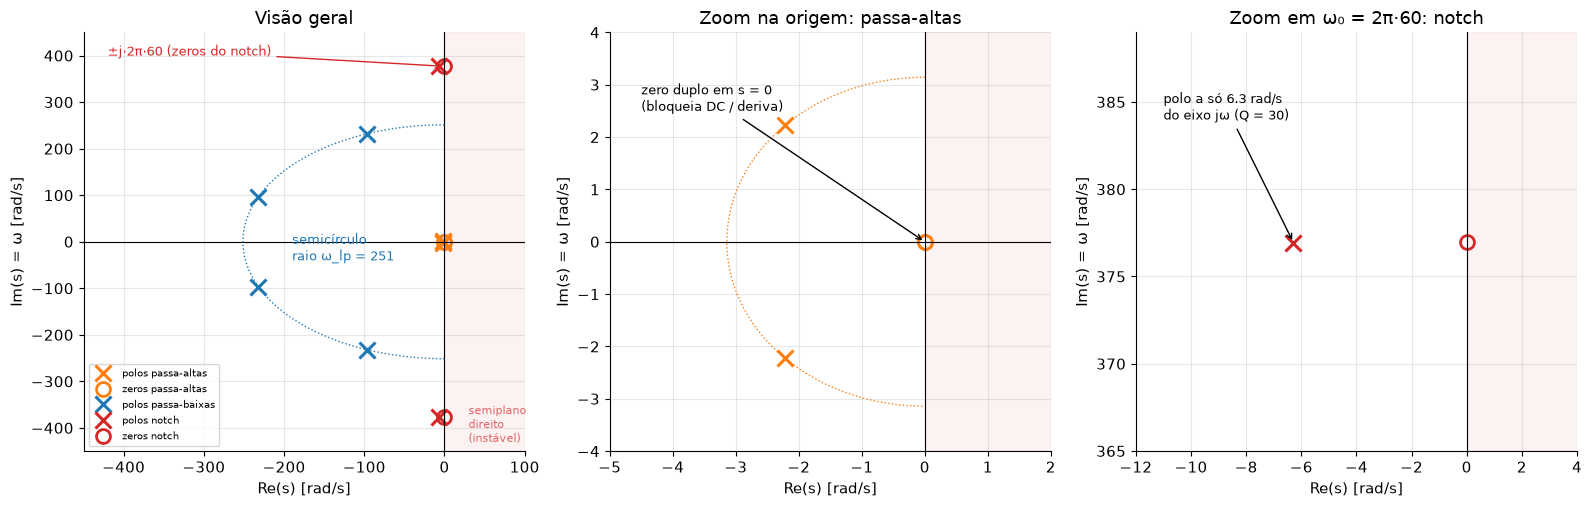

In [23]:
fig, axs = plt.subplots(1, 3, figsize=(16, 5.2))
estilos = {"passa-altas": "C1", "passa-baixas": "C0", "notch": "C3"}
def desenhar(ax, lim, titulo):
    for nome, zs, ps in [("passa-altas", z_hp, p_hp), ("passa-baixas", z_lp, p_lp), ("notch", z_n, p_n)]:
        ax.plot(ps.real, ps.imag, "x", ms=11, mew=2.2, color=estilos[nome], label=f"polos {nome}")
        if len(zs):
            ax.plot(zs.real, zs.imag, "o", ms=10, mfc="none", mew=2, color=estilos[nome], label=f"zeros {nome}")
    ax.axhline(0, color="k", lw=0.8); ax.axvline(0, color="k", lw=0.8)
    ax.axvspan(0, lim[0][1] if lim[0][1] > 0 else 0, color="C3", alpha=0.06)
    ax.set_xlim(*lim[0]); ax.set_ylim(*lim[1]); ax.set_title(titulo)
    ax.set_xlabel("Re(s) [rad/s]"); ax.set_ylabel("Im(s) = ω [rad/s]")

desenhar(axs[0], ((-450, 100), (-450, 450)), "Visão geral")
th = np.linspace(np.pi/2, 3*np.pi/2, 200)
axs[0].plot(w_lp*np.cos(th), w_lp*np.sin(th), ":", color="C0", lw=1)
axs[0].text(-190, -40, f"semicírculo\nraio ω_lp = {w_lp:.0f}", color="C0", fontsize=9)
for wv, txt in [(w0, "±j·2π·60 (zeros do notch)")]:
    axs[0].annotate(txt, xy=(0, wv), xytext=(-420, 400), arrowprops=dict(arrowstyle="->", color="C3"), color="C3", fontsize=9)
axs[0].text(30, -430, "semiplano\ndireito\n(instável)", color="C3", fontsize=8, alpha=0.7)
axs[0].legend(fontsize=7.5, loc="lower left")

desenhar(axs[1], ((-5, 2), (-4, 4)), "Zoom na origem: passa-altas")
axs[1].plot(w_hp*np.cos(th), w_hp*np.sin(th), ":", color="C1", lw=1)
axs[1].annotate("zero duplo em s = 0\n(bloqueia DC / deriva)", xy=(0, 0), xytext=(-4.5, 2.5), arrowprops=dict(arrowstyle="->"), fontsize=9)

desenhar(axs[2], ((-12, 4), (w0 - 12, w0 + 12)), "Zoom em ω₀ = 2π·60: notch")
axs[2].annotate(f"polo a só {abs(p_n[0].real):.1f} rad/s\ndo eixo jω (Q = {Q:.0f})", xy=(p_n.real.max(), p_n.imag.max()),
                xytext=(-11, w0 + 7), arrowprops=dict(arrowstyle="->"), fontsize=9)
fig.tight_layout(); salvar(fig, "e4_polos_zeros"); plt.show()

## 4.3 Interpretando o mapa: a resposta em frequência vista "geometricamente"
Escrevendo $H(s) = k\,\dfrac{\prod_i (s - z_i)}{\prod_j (s - p_j)}$ e fazendo $s = j\omega$:
$$
|H(j\omega)| = k\,\frac{\prod_i \text{(distância de } j\omega \text{ até o zero } z_i)}{\prod_j \text{(distância de } j\omega \text{ até o polo } p_j)}
$$
Percorrer as frequências é **andar para cima no eixo imaginário**: perto de um zero o ganho despenca; perto de um polo ele sobe. Conferimos essa fórmula contra o cálculo direto:

f =    0.1 Hz: produto de distâncias = 0.039968 | freqs_zpk = 0.039968
f =   10.0 Hz: produto de distâncias = 0.999973 | freqs_zpk = 0.999973
f =   60.0 Hz: produto de distâncias = 0.000000 | freqs_zpk = 0.000000
f =  120.0 Hz: produto de distâncias = 0.012342 | freqs_zpk = 0.012342


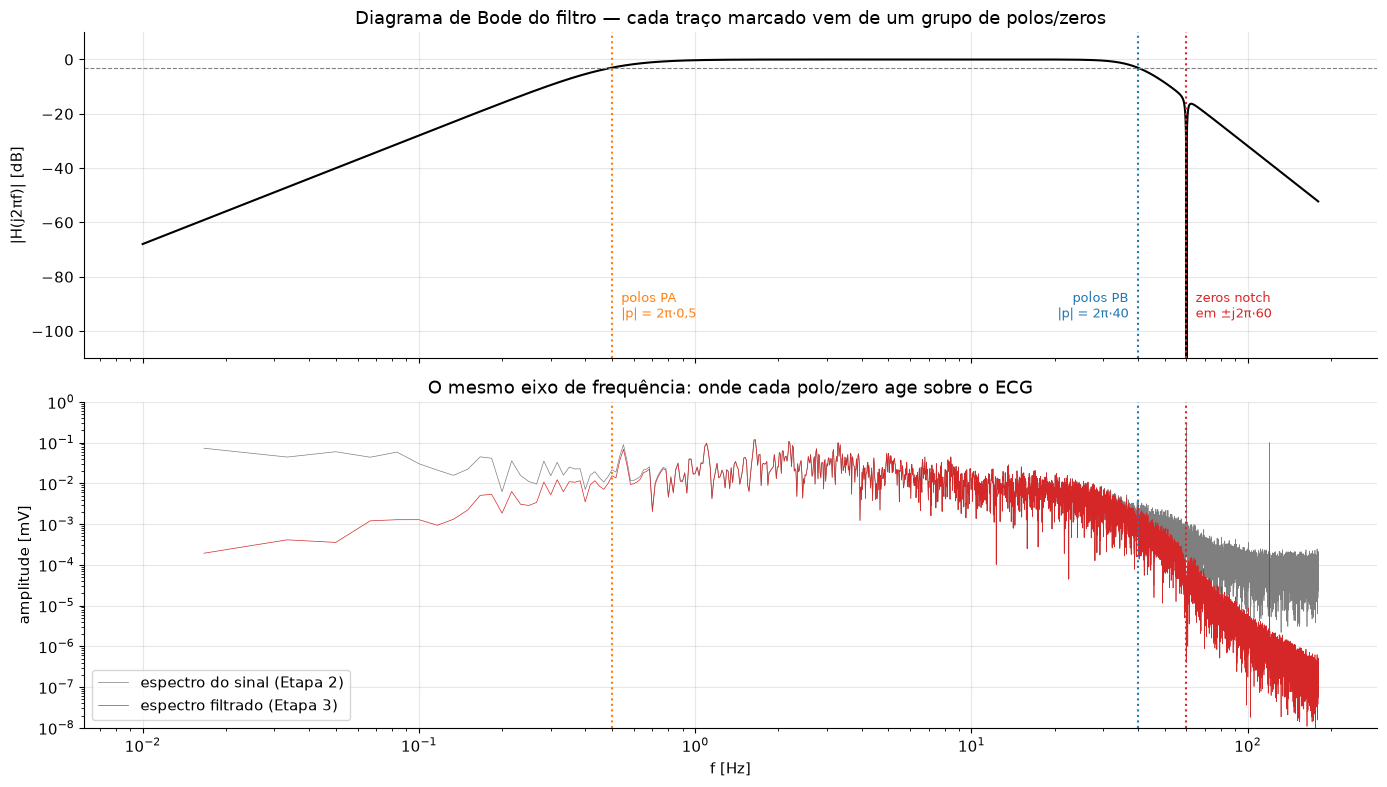

In [24]:
for fr in [0.1, 10, 60, 120]:
    jw = 1j*2*np.pi*fr
    geom = abs(k_tot) * np.prod(np.abs(jw - z_tot)) / np.prod(np.abs(jw - p_tot))
    print(f"f = {fr:6.1f} Hz: produto de distâncias = {geom:.6f} | freqs_zpk = {abs(H_de_f([fr])[0]):.6f}")

fig, (a1, a2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
fb = np.unique(np.concatenate([np.logspace(-2, np.log10(fs/2), 4000), np.linspace(59, 61, 4001)]))  # malha fina no notch
Hb = H_de_f(fb)
a1.semilogx(fb, 20*np.log10(np.abs(Hb) + 1e-12), color="k")
for fr, cor, txt, ha in [(fc_hp, "C1", "polos PA\n|p| = 2π·0,5", "left"), (fc_lp, "C0", "polos PB\n|p| = 2π·40", "right"),
                         (f_notch, "C3", "zeros notch\nem ±j2π·60", "left")]:
    a1.axvline(fr, color=cor, ls=":")
    a1.text(fr*1.08 if ha == "left" else fr/1.08, -95, txt, color=cor, fontsize=9, ha=ha)
a1.axhline(-3, color="0.5", ls="--", lw=0.8)
a1.set_ylim(-110, 10); a1.set_ylabel("|H(j2πf)| [dB]")
a1.set_title("Diagrama de Bode do filtro — cada traço marcado vem de um grupo de polos/zeros")

a2.loglog(f[1:], Aw_x[1:], lw=0.5, color="C7", label="espectro do sinal (Etapa 2)")
a2.loglog(f[1:], Aw_y[1:], lw=0.5, color="C3", label="espectro filtrado (Etapa 3)")
a2.set_ylim(1e-8, 1); a2.set_xlabel("f [Hz]"); a2.set_ylabel("amplitude [mV]")
a2.set_title("O mesmo eixo de frequência: onde cada polo/zero age sobre o ECG")
a2.legend(loc="lower left")
for fr, cor in [(fc_hp, "C1"), (fc_lp, "C0"), (f_notch, "C3")]:
    a2.axvline(fr, color=cor, ls=":")
fig.tight_layout(); salvar(fig, "e4_bode_vs_espectro"); plt.show()

## 4.4 Estabilidade no tempo: resposta ao impulso e ao degrau
Estabilidade BIBO ⇔ $\int |h(t)|\,dt < \infty$ ⇔ todos os polos com $\mathrm{Re}(p) < 0$. Pela expansão em frações parciais, $h(t) = \sum_j r_j\,e^{p_j t}$: cada polo contribui um modo que decai com constante de tempo $1/|\mathrm{Re}(p_j)|$.

passa-altas : constante de tempo dos modos =    450.2 ms
passa-baixas: constante de tempo dos modos =     10.4 ms
notch       : constante de tempo dos modos =    159.2 ms
∫|h(t)|dt (0 a 3 s) ≈ 2.571  → finito


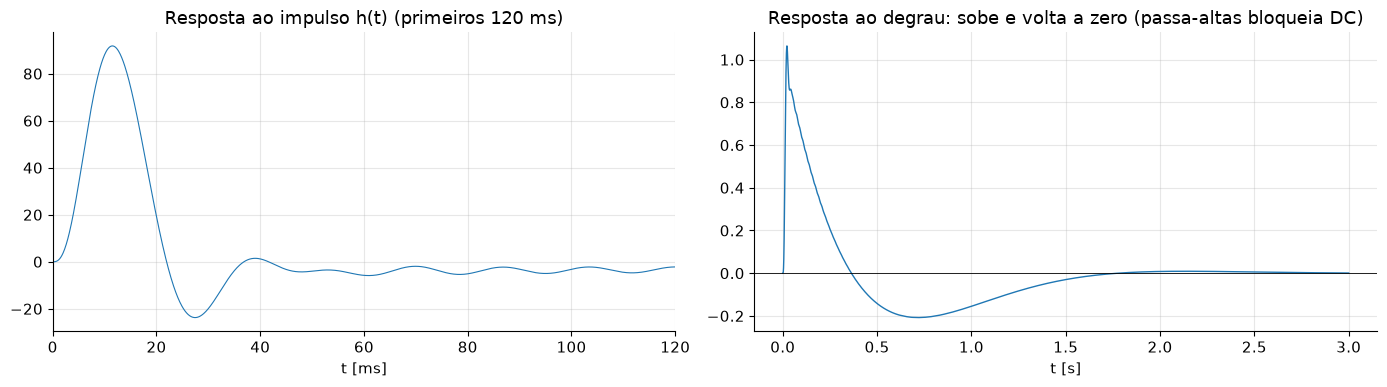

In [25]:
sistema = signal.ZerosPolesGain(z_tot, p_tot, k_tot)
t_resp = np.linspace(0, 3, 30000)
_, h_imp = signal.impulse(sistema, T=t_resp)
_, h_deg = signal.step(sistema, T=t_resp)

taus = 1/np.abs(p_tot.real)
for nome, ps in [("passa-altas", p_hp), ("passa-baixas", p_lp), ("notch", p_n)]:
    print(f"{nome:12s}: constante de tempo dos modos = {1e3/np.abs(ps.real).min():8.1f} ms")
print(f"∫|h(t)|dt (0 a 3 s) ≈ {np.trapezoid(np.abs(h_imp), t_resp):.3f}  → finito")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4))
a1.plot(t_resp*1e3, h_imp, lw=0.8); a1.set_xlim(0, 120)
a1.set_title("Resposta ao impulso h(t) (primeiros 120 ms)"); a1.set_xlabel("t [ms]")
a2.plot(t_resp, h_deg, lw=1); a2.axhline(0, color="k", lw=0.6)
a2.set_title("Resposta ao degrau: sobe e volta a zero (passa-altas bloqueia DC)"); a2.set_xlabel("t [s]")
fig.tight_layout(); salvar(fig, "e4_respostas_tempo"); plt.show()

**Interpretação — a mesma história em duas linguagens.**

| O que vimos no espectro (Etapa 2/3) | Onde está no plano $s$ (Etapa 4) |
|---|---|
| Deriva < 0,5 Hz removida | **Zero duplo em $s = 0$** (ganho nulo em DC) e **par de polos a raio $2\pi\cdot0{,}5$** — onde o passa-altas "liga" |
| Faixa 0,5–40 Hz praticamente intacta (plana) | Os 4 polos do passa-baixas estão sobre um **semicírculo de raio $2\pi\cdot40$** (padrão Butterworth): ao subir pelo eixo $j\omega$ abaixo de 40 Hz, as distâncias até eles mudam pouco ⇒ ganho ≈ 1 |
| Queda acima de 40 Hz, 120 Hz a ≈ −38 dB | Acima de $|p| = 2\pi\cdot40$ o ponto $j\omega$ se afasta dos 4 polos ⇒ ganho cai 80 dB/década (4 polos × 20 dB) |
| **Vale profundo em 60 Hz** | **Zeros exatamente sobre o eixo imaginário em $\pm j2\pi\cdot60$**: em $\omega = \omega_0$ a distância ao zero é 0 ⇒ $|H| = 0$ |
| O vale é estreito (não afeta 55 ou 65 Hz) | Os polos do notch estão **colados aos zeros**, a só $\omega_0/2Q$ do eixo; longe de 60 Hz, a distância ao polo ≈ distância ao zero e eles se cancelam ⇒ $|H| \approx 1$. Maior $Q$ ⇒ polos mais perto ⇒ vale mais estreito |

**Estabilidade.** Todos os 8 polos têm parte real negativa ⇒ o sistema é **estável**: a resposta ao impulso é uma soma de exponenciais amortecidas e vai a zero. Os polos mais próximos do eixo $j\omega$ determinam os modos mais lentos: os do passa-altas (constante de tempo de centenas de ms, por isso o degrau demora para voltar a zero) e os do notch (oscilam em 60 Hz e decaem em ~160 ms, o "tempo de assentamento" do notch). Um polo no semiplano direito geraria um termo $e^{+at}$ crescente — o "filtro" amplificaria qualquer ruído até saturar.

## Conclusão
* **Etapa 1:** um sinal periódico é uma soma de senoides ortogonais; cada coeficiente é uma projeção. Truncar a série gera Gibbs — lição usada para escolher filtros suaves.
* **Etapa 2:** a FFT revelou, separados, os três componentes que no tempo estavam misturados (batimento + harmônicos, deriva, rede elétrica). A taxa de amostragem fixa o eixo de frequência e o limite de Nyquist; amostrar abaixo dele "dobra" 60 Hz para dentro do ECG.
* **Etapa 3:** multiplicar o espectro por $|H|$ e voltar ao tempo pela FFT inversa removeu deriva e interferência mantendo a morfologia do ECG (validado por um filtro digital independente).
* **Etapa 4:** o mesmo filtro, escrito como $H(s)$, tem seu comportamento inteiro "desenhado" no plano $s$: zeros no eixo $j\omega$ produzem nulos, polos definem cortes e ressonâncias, e polos no semiplano esquerdo garantem estabilidade. Espectro e mapa de polos/zeros contam **a mesma história**.